# Phase 0 — Teacher VLM Selection & Threshold Analysis

**Low-Light Object Detection via Decoupled VLM Pseudo-Labelling (RF-DETR pipeline)**

Phase 0 empirically decides, before any pseudo-labels are generated at scale:

1. **Which annotation teacher** — MM Grounding DINO, OWLv2, or YOLO-World v8.
2. **Which image condition** — raw ExDark or Zero-DCE-enhanced.
3. **Which confidence threshold** to filter pseudo-labels.

It runs all three teachers zero-shot on a stratified ExDark sample under both conditions, measuring per-class confidence distributions, precision @ thresholds, confidence–IoU calibration, and per-class survival rate.

## 1. Install dependencies

Pins `transformers` to a stable 4.5x line (required for MM Grounding DINO, capped below 5.0 for API compatibility) and constrains numpy/pandas to the versions Colab's pre-installed packages expect. Adds `ultralytics` for YOLO-World v8.


In [ ]:
# MM Grounding DINO requires transformers >= 4.55 (added Aug 2025); we cap below 5.0 to keep
# the 4.x post-processing API the wrappers use. ultralytics adds YOLO-World v8.
!pip install -q \
    "transformers>=4.55,<5.0" \
    "numpy>=1.26,<2.1" \
    "pandas>=2.0,<2.3" \
    "pillow" "matplotlib" "seaborn" "scipy" "tqdm" "gdown" "ultralytics"
# torch / torchvision ship with the Colab runtime already built against the runtime's CUDA —
# we do NOT reinstall them, to avoid breaking those pre-built wheels.

import transformers, torch, numpy, pandas
print("transformers:", transformers.__version__, "(need >= 4.55 for MM Grounding DINO)")
print("torch:", torch.__version__)
print("numpy:", numpy.__version__, "| pandas:", pandas.__version__)
print("CUDA available:", torch.cuda.is_available())

# Fail fast with a clear message if transformers is too old to contain MM Grounding DINO
from packaging import version
assert version.parse(transformers.__version__) >= version.parse("4.55"), \
    "transformers is too old for MM Grounding DINO; restart runtime after the pip install completes."


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 76.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 57.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 27.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.20.0 requires huggingface-hub<2.0,>=1.2.0, but you have huggingface-hub 0.36.2 which is incompatible.
transformers: 4.57.6 (need >= 4.55 for MM Grounding DINO)
torch: 2.11.0+cu128
numpy: 2.0.2 | pandas: 2.2.2
CUDA available: True


## 2. Configuration

All paths and hyper-parameters live here; everything downstream reads from this cell. `PROMPT_MAP` translates each ExDark class into the natural-language prompt the VLMs expect (e.g. *People → "person"*), and predictions are mapped back to the canonical ExDark label.


In [ ]:
from dataclasses import dataclass, field

# ── ExDark canonical classes (12) ──
EXDARK_CLASSES = ["Bicycle", "Boat", "Bottle", "Bus", "Car", "Cat",
                  "Chair", "Cup", "Dog", "Motorbike", "People", "Table"]

# ── VLM prompt phrasing per class (natural language improves zero-shot recall) ──
PROMPT_MAP = {
    "Bicycle": "bicycle", "Boat": "boat", "Bottle": "bottle", "Bus": "bus",
    "Car": "car", "Cat": "cat", "Chair": "chair", "Cup": "cup", "Dog": "dog",
    "Motorbike": "motorcycle", "People": "person", "Table": "table",
}
# Reverse map: prompt phrase -> ExDark class
PROMPT_TO_CLASS = {v: k for k, v in PROMPT_MAP.items()}
PROMPTS = [PROMPT_MAP[c] for c in EXDARK_CLASSES]

@dataclass
class Config:
    # Dataset locations — set automatically in Section 3 after mounting Drive.
    # Defaults point at the cached copy inside your Google Drive.
    images_dir: str = "/content/drive/MyDrive/ExDark_dataset/ExDark"        # <class>/<image> subfolders
    annot_dir:  str = "/content/drive/MyDrive/ExDark_dataset/ExDark_Annno"  # <class>/<image>.txt subfolders (official folder is 'Annno')

    # Stratified sampling
    sample_per_class: int = 50   # 600 images total (12 classes × 50)
    random_seed: int = 42

    # Teacher model ids
    gdino_id: str = "openmmlab-community/mm_grounding_dino_tiny_o365v1_goldg_v3det"
    owlv2_id: str = "google/owlv2-base-patch16-ensemble"
    yoloworld_id: str = "yolov8x-worldv2.pt"   # YOLO-World v8, added from the teacher-comparison probe

    # Evaluation
    thresholds: tuple = (0.55, 0.60, 0.65, 0.70, 0.75, 0.80)
    iou_match: float = 0.50      # IoU >= this counts a prediction as matching a GT box
    infer_threshold: float = 0.05  # keep all boxes above this at inference; filter later in analysis

    # Zero-DCE
    zerodce_weights_url: str = ("https://raw.githubusercontent.com/Li-Chongyi/"
                                "Zero-DCE/master/Zero-DCE_code/snapshots/Epoch99.pth")
    zerodce_max_side: int = 1200  # downscale very large images before enhancement for memory safety

    # Output location — a NEW subfolder under Drive (kept separate from prior Phase 0 runs
    # so results that include the YOLO-World teacher don't overwrite the earlier dual-teacher run)
    output_subdir: str = "phase0_outputs_yoloworld_v8"

CFG = Config()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
print("Classes:", EXDARK_CLASSES)
print("Prompts:", PROMPTS)


Device: cuda
Classes: ['Bicycle', 'Boat', 'Bottle', 'Bus', 'Car', 'Cat', 'Chair', 'Cup', 'Dog', 'Motorbike', 'People', 'Table']
Prompts: ['bicycle', 'boat', 'bottle', 'bus', 'car', 'cat', 'chair', 'cup', 'dog', 'motorcycle', 'person', 'table']


## 3. Point at the ExDark dataset in Google Drive

Mounts Drive, points the config at `MyDrive/ExDark_dataset/ExDark` (images) and `ExDark_Annno` (annotations, Piotr's toolbox format: a header line then `class_name l t w h [7 unused columns]`), verifies the dataset is complete, and creates the new output subfolder for this run.


In [ ]:
import os, glob

# ── 3.1 Mount Google Drive ──
from google.colab import drive
drive.mount("/content/drive")

# ── 3.2 Point the config at the already-uploaded folders ──
DRIVE_ROOT = "/content/drive/MyDrive/ExDark_dataset"
CFG.images_dir = os.path.join(DRIVE_ROOT, "ExDark")         # images:      <class>/<image>
CFG.annot_dir  = os.path.join(DRIVE_ROOT, "ExDark_Annno")   # annotations: <class>/<image>.txt

# ── 3.3 New output subfolder for this run (adds the YOLO-World teacher) ──
PHASE0_OUTPUT_DIR = os.path.join(DRIVE_ROOT, CFG.output_subdir)
os.makedirs(PHASE0_OUTPUT_DIR, exist_ok=True)

print("images_dir:", CFG.images_dir)
print("annot_dir :", CFG.annot_dir)
print("outputs   :", PHASE0_OUTPUT_DIR)
print("Drive contents:", os.listdir(DRIVE_ROOT))


Mounted at /content/drive
images_dir: /content/drive/MyDrive/ExDark_dataset/ExDark
annot_dir : /content/drive/MyDrive/ExDark_dataset/ExDark_Annno
outputs   : /content/drive/MyDrive/ExDark_dataset/phase0_outputs_yoloworld_v8
Drive contents: ['ExDark_groundtruth.zip', 'ExDark_images.zip', '__MACOSX', 'ExDark', 'ExDark_Annno', 'weights', 'phase0_sample', 'phase1_outputs', 'ExDark_enhanced', 'phase1_predictions', 'phase1_datasets_zip', 'stage2_checkpoints', 'stage2_results', 'stage2_checkpoints_25ep', 'stage2_results_25ep', 'teacher_probe_results', 'refinement_probe_results', 'phase1b_yw_predictions', 'phase1b_yw_outputs', 'probe_enh_results', 'probe_enhanced', 'probe_enh_checkpoints', 'phase0_outputs_yoloworld_v8']


In [ ]:
# ── 3.3 Verify the dataset is complete ──
EXPECTED_TOTAL_IMAGES = 7363
PER_CLASS_EXPECTED = {  # official counts from the dataset README
    "Bicycle":652, "Boat":679, "Bottle":547, "Bus":527, "Car":638, "Cat":735,
    "Chair":648, "Cup":519, "Dog":801, "Motorbike":503, "People":609, "Table":505,
}

def find_class_dir(root, cls):
    for cand in [cls, cls.lower(), cls.replace(" ", "_")]:
        p = os.path.join(root, cand)
        if os.path.isdir(p):
            return p
    return None

def verify_complete(cfg):
    if not os.path.isdir(cfg.images_dir):
        print(f"[MISSING] images_dir: {cfg.images_dir}"); return False
    if not os.path.isdir(cfg.annot_dir):
        print(f"[MISSING] annot_dir: {cfg.annot_dir}"); return False
    print(f"{'Class':<10} {'images':>8} {'expected':>9} {'annots':>8}")
    print("-" * 40)
    total_img, problems = 0, []
    for c in EXDARK_CLASSES:
        idir, adir = find_class_dir(cfg.images_dir, c), find_class_dir(cfg.annot_dir, c)
        n_img = len([p for p in glob.glob(os.path.join(idir, "*"))
                     if p.lower().endswith((".png",".jpg",".jpeg",".bmp"))]) if idir else 0
        n_ann = len(glob.glob(os.path.join(adir, "*.txt"))) if adir else 0
        exp = PER_CLASS_EXPECTED[c]; total_img += n_img
        flag = "" if (n_img == exp and n_ann >= exp) else "  <-- MISMATCH"
        if flag: problems.append(c)
        print(f"{c:<10} {n_img:>8} {exp:>9} {n_ann:>8}{flag}")
    print("-" * 40)
    print(f"{'TOTAL':<10} {total_img:>8} {EXPECTED_TOTAL_IMAGES:>9}")
    if total_img != EXPECTED_TOTAL_IMAGES or problems:
        print("\n[INCOMPLETE] Counts don't match the official dataset. Check that the folders in")
        print("DRIVE_ROOT are named 'ExDark' and 'ExDark_Annno' and fully extracted.")
        return False
    print("\n[OK] Full ExDark dataset present (7,363 images + annotations).")
    return True

assert verify_complete(CFG), "Dataset incomplete — fix the paths above before continuing."


Class        images  expected   annots
----------------------------------------
Bicycle         652       652      652
Boat            679       679      679
Bottle          547       547      547
Bus             527       527      527
Car             638       638      638
Cat             735       735      735
Chair           648       648      648
Cup             519       519      519
Dog             801       801      801
Motorbike       503       503      503
People          609       609      609
Table           505       505      505
----------------------------------------
TOTAL          7363      7363

[OK] Full ExDark dataset present (7,363 images + annotations).


## 4. Parse annotations and build a stratified sample

Draws up to `sample_per_class` images per class (stratified, seed 42) so rare classes are represented for calibration. The manifest is cached to `MyDrive/ExDark_dataset/phase0_sample/sample_manifest.json` and reused across runs unless `sample_per_class` or `random_seed` changes.


In [ ]:
import random, json, hashlib
from PIL import Image

def parse_bbgt(txt_path):
    # Parse an ExDark bbGt annotation file -> list of (ExDark_class, [x1,y1,x2,y2]).
    boxes = []
    if not os.path.isfile(txt_path):
        return boxes
    with open(txt_path, "r", errors="ignore") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("%") or line.lower().startswith("class"):
                continue
            parts = line.split()
            if len(parts) < 5:
                continue
            label = parts[0]
            # normalise label capitalisation to canonical ExDark class
            canon = next((c for c in EXDARK_CLASSES if c.lower() == label.lower()), None)
            if canon is None:
                continue
            try:
                l, t, w, h = map(float, parts[1:5])
            except ValueError:
                continue
            boxes.append((canon, [l, t, l + w, t + h]))
    return boxes

def annot_path_for(cfg, cls, image_filename):
    d = find_class_dir(cfg.annot_dir, cls)
    if d is None:
        return None
    # ExDark annotations are typically named <image>.txt
    cand = os.path.join(d, image_filename + ".txt")
    if os.path.isfile(cand):
        return cand
    stem = os.path.splitext(image_filename)[0]
    for alt in [stem + ".txt", stem + ".png.txt", stem + ".jpg.txt"]:
        p = os.path.join(d, alt)
        if os.path.isfile(p):
            return p
    return None

def _build_sample_fresh(cfg):
    random.seed(cfg.random_seed)
    samples = []  # dicts: {path, primary_class, filename, gt: [(cls,[x1,y1,x2,y2])]}
    for c in EXDARK_CLASSES:
        img_dir = find_class_dir(cfg.images_dir, c)
        if img_dir is None:
            continue
        imgs = sorted(glob.glob(os.path.join(img_dir, "*")))
        imgs = [p for p in imgs if p.lower().endswith((".png", ".jpg", ".jpeg", ".bmp"))]
        random.shuffle(imgs)
        for p in imgs[: cfg.sample_per_class]:
            fn = os.path.basename(p)
            gt = parse_bbgt(annot_path_for(cfg, c, fn))
            samples.append({"path": p, "primary_class": c, "filename": fn, "gt": gt})
    random.shuffle(samples)
    return samples

# ── Sample caching to a dedicated Drive folder ──
# Saved to its own folder (separate from the raw dataset) so the stratified sample used for
# Phase 0 can be retrieved instantly on a later run, or shared/inspected without re-deriving it.
SAMPLE_CACHE_DIR = "/content/drive/MyDrive/ExDark_dataset/phase0_sample"
os.makedirs(SAMPLE_CACHE_DIR, exist_ok=True)
SAMPLE_MANIFEST_PATH = os.path.join(SAMPLE_CACHE_DIR, "sample_manifest.json")

def _sample_config_fingerprint(cfg):
    # Ties the cached sample to the exact parameters that produced it, so changing
    # sample_per_class / random_seed / dataset paths correctly triggers a rebuild
    # instead of silently reusing a stale sample.
    key = f"{cfg.sample_per_class}|{cfg.random_seed}|{cfg.images_dir}|{cfg.annot_dir}"
    return hashlib.md5(key.encode()).hexdigest()

def build_sample(cfg):
    fingerprint = _sample_config_fingerprint(cfg)

    if os.path.isfile(SAMPLE_MANIFEST_PATH):
        try:
            with open(SAMPLE_MANIFEST_PATH, "r") as f:
                manifest = json.load(f)
            if manifest.get("fingerprint") == fingerprint:
                print(f"[cached] Loading stratified sample from {SAMPLE_MANIFEST_PATH}")
                samples = manifest["samples"]
                # JSON round-trips tuples as lists; restore gt boxes as (class, [x1,y1,x2,y2]) tuples
                for s in samples:
                    s["gt"] = [(g[0], g[1]) for g in s["gt"]]
                return samples
            else:
                print("[cache miss] Sample manifest exists but parameters changed — rebuilding.")
        except Exception as e:
            print(f"[cache miss] Could not read existing manifest ({e}) — rebuilding.")

    print("Building stratified sample from scratch...")
    samples = _build_sample_fresh(cfg)

    manifest = {"fingerprint": fingerprint, "sample_per_class": cfg.sample_per_class,
                "random_seed": cfg.random_seed, "images_dir": cfg.images_dir,
                "annot_dir": cfg.annot_dir, "n_samples": len(samples), "samples": samples}
    with open(SAMPLE_MANIFEST_PATH, "w") as f:
        json.dump(manifest, f)
    print(f"Saved sample manifest to {SAMPLE_MANIFEST_PATH} for future reuse.")

    return samples

SAMPLES = build_sample(CFG)
print(f"Sampled {len(SAMPLES)} images.")
gt_boxes = sum(len(s['gt']) for s in SAMPLES)
print(f"Total ground-truth boxes across sample: {gt_boxes}")


[cached] Loading stratified sample from /content/drive/MyDrive/ExDark_dataset/phase0_sample/sample_manifest.json
Sampled 600 images.
Total ground-truth boxes across sample: 1996


## 5. Zero-DCE enhancement (offline, decoupled)

Zero-DCE performs unsupervised, zero-reference low-light enhancement, applied offline and fully decoupled from the detector. Enhanced copies of sampled images are cached in memory.


[cached] Zero-DCE weights: /content/drive/MyDrive/ExDark_dataset/weights/zerodce_Epoch99.pth
Zero-DCE loaded.


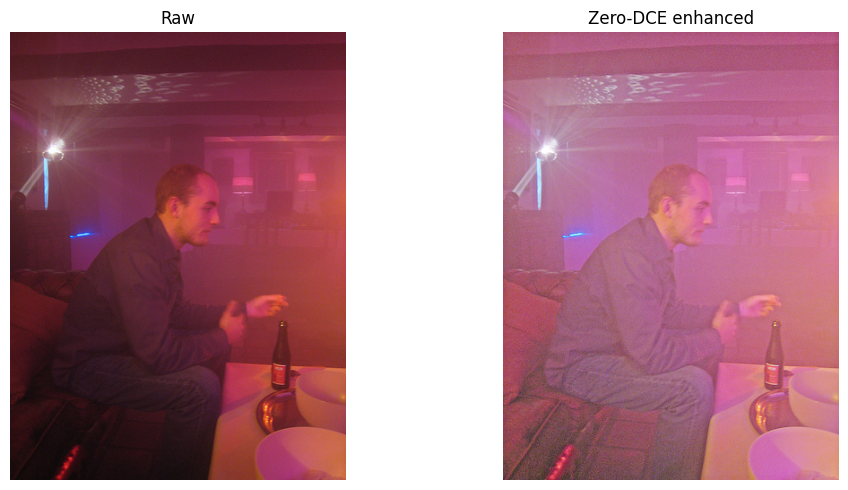

In [ ]:
import torch.nn as nn
import numpy as np

class DCE_Net(nn.Module):
    '''Official Zero-DCE enhance_net_nopool architecture.'''
    def __init__(self, number_f=32):
        super().__init__()
        self.relu = nn.ReLU(inplace=True)
        self.e_conv1 = nn.Conv2d(3, number_f, 3, 1, 1, bias=True)
        self.e_conv2 = nn.Conv2d(number_f, number_f, 3, 1, 1, bias=True)
        self.e_conv3 = nn.Conv2d(number_f, number_f, 3, 1, 1, bias=True)
        self.e_conv4 = nn.Conv2d(number_f, number_f, 3, 1, 1, bias=True)
        self.e_conv5 = nn.Conv2d(number_f * 2, number_f, 3, 1, 1, bias=True)
        self.e_conv6 = nn.Conv2d(number_f * 2, number_f, 3, 1, 1, bias=True)
        self.e_conv7 = nn.Conv2d(number_f * 2, 24, 3, 1, 1, bias=True)

    def forward(self, x):
        x1 = self.relu(self.e_conv1(x))
        x2 = self.relu(self.e_conv2(x1))
        x3 = self.relu(self.e_conv3(x2))
        x4 = self.relu(self.e_conv4(x3))
        x5 = self.relu(self.e_conv5(torch.cat([x3, x4], 1)))
        x6 = self.relu(self.e_conv6(torch.cat([x2, x5], 1)))
        x_r = torch.tanh(self.e_conv7(torch.cat([x1, x6], 1)))
        r = torch.split(x_r, 3, dim=1)
        for i in range(8):
            x = x + r[i] * (torch.pow(x, 2) - x)
        return x  # enhanced image in [0,1]

def load_zerodce(cfg):
    import urllib.request

    # Cache weights in Drive if it's mounted, else in /content
    wdir = ("/content/drive/MyDrive/ExDark_dataset/weights"
            if os.path.isdir("/content/drive/MyDrive") else "/content/weights")
    os.makedirs(wdir, exist_ok=True)
    wpath = os.path.join(wdir, "zerodce_Epoch99.pth")

    def _valid_checkpoint(path):
        # A valid .pth is >100 KB and torch-loadable; an HTML error page is small text
        if not os.path.isfile(path) or os.path.getsize(path) < 100_000:
            return False
        try:
            torch.load(path, map_location="cpu"); return True
        except Exception:
            return False

    if not _valid_checkpoint(wpath):
        print("Downloading Zero-DCE weights...")
        got = False
        # Attempt 1: direct raw.githubusercontent download
        try:
            req = urllib.request.Request(cfg.zerodce_weights_url,
                                         headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as r, open(wpath, "wb") as f:
                f.write(r.read())
            got = _valid_checkpoint(wpath)
        except Exception as e:
            print("  direct download failed:", e)
        # Attempt 2: wget fallback
        if not got:
            print("  retrying with wget...")
            os.system(f'wget -q -O "{wpath}" "{cfg.zerodce_weights_url}"')
            got = _valid_checkpoint(wpath)
        if not got:
            raise RuntimeError(
                "Could not obtain a valid Zero-DCE checkpoint. Download 'Epoch99.pth' "
                "manually from https://github.com/Li-Chongyi/Zero-DCE/tree/master/"
                "Zero-DCE_code/snapshots and place it at:\n  " + wpath)
        print("  weights verified:", wpath)
    else:
        print("[cached] Zero-DCE weights:", wpath)

    state = torch.load(wpath, map_location="cpu")
    # strip possible 'module.' prefixes from DataParallel training
    state = { (k[7:] if k.startswith("module.") else k): v for k, v in state.items() }
    net = DCE_Net()
    net.load_state_dict(state)
    net.eval().to(DEVICE)
    return net

ZERODCE = load_zerodce(CFG)
print("Zero-DCE loaded.")

@torch.no_grad()
def enhance_image(pil_img, cfg=CFG):
    img = pil_img.convert("RGB")
    w, h = img.size
    scale = min(1.0, cfg.zerodce_max_side / max(w, h))
    if scale < 1.0:
        img = img.resize((int(w * scale), int(h * scale)), Image.BILINEAR)
    arr = np.asarray(img).astype(np.float32) / 255.0
    ten = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).to(DEVICE)
    out = ZERODCE(ten).clamp(0, 1)
    out = (out.squeeze(0).permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)
    enh = Image.fromarray(out)
    if scale < 1.0:
        enh = enh.resize((w, h), Image.BILINEAR)  # restore original size for consistent GT coords
    return enh

# Quick visual sanity check on one sample
import matplotlib.pyplot as plt
_s = SAMPLES[0]
_raw = Image.open(_s["path"]).convert("RGB")
_enh = enhance_image(_raw)
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(_raw); ax[0].set_title("Raw"); ax[0].axis("off")
ax[1].imshow(_enh); ax[1].set_title("Zero-DCE enhanced"); ax[1].axis("off")
plt.tight_layout(); plt.show()


## 6. Load the three teachers

All three are open-vocabulary detectors that produce per-box confidence scores from a dedicated detection head — the property that makes them valid pseudo-label sources. MM Grounding DINO and OWLv2 load via `transformers`; YOLO-World v8 loads via `ultralytics`. All three are loaded once and reused across both image conditions.


In [ ]:
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection
from ultralytics import YOLOWorld

print("Loading Teacher A — MM Grounding DINO ...")
gdino_proc = AutoProcessor.from_pretrained(CFG.gdino_id)
gdino_model = AutoModelForZeroShotObjectDetection.from_pretrained(CFG.gdino_id).to(DEVICE).eval()

print("Loading Teacher B — OWLv2 ...")
owl_proc = AutoProcessor.from_pretrained(CFG.owlv2_id)
owl_model = AutoModelForZeroShotObjectDetection.from_pretrained(CFG.owlv2_id).to(DEVICE).eval()

print("Loading Teacher C — YOLO-World v8 ...")
yoloworld_model = YOLOWorld(CFG.yoloworld_id)
yoloworld_model.set_classes(PROMPTS)   # index i -> EXDARK_CLASSES[i]

print("All three teachers loaded.")


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Loading Teacher A — MM Grounding DINO ...


preprocessor_config.json:   0%|          | 0.00/511 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/620M [00:00<?, ?B/s]

Loading Teacher C — YOLO-World v8 ...
requirements: Ultralytics requirement ['git+https://github.com/ultralytics/CLIP.git'] not found, attempting AutoUpdate...
Using Python 3.12.13 environment at: /usr
Resolved 37 packages in 843ms
Prepared 2 packages in 2.14s
Installed 2 packages in 1ms
 + clip==1.0 (from git+https://github.com/ultralytics/CLIP.git@c4b6ea0932a2c0f39a0fa528af5ec4982ff15cab)
 + ftfy==6.3.1

requirements: AutoUpdate success ✅ 3.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect



100%|████████████████████████████████████████| 338M/338M [00:01<00:00, 232MiB/s]


All three teachers loaded.


### 6.1 Inference wrappers

Each wrapper returns a uniform list of detections: `(ExDark_class, [x1,y1,x2,y2], score)`. Everything above a very low `infer_threshold` is kept, so one inference pass supports the full threshold sweep.


In [ ]:
def _labels_to_classes(res, n_boxes):
    '''Return a list of ExDark class names (or None) for each detected box,
    robust to whether the processor returned text_labels, integer labels, or None.'''
    labels = res.get("text_labels", None)
    if labels is None:
        labels = res.get("labels", None)
    out = []
    if labels is None:
        return [None] * n_boxes
    for lab in labels:
        if isinstance(lab, str):
            phrase = lab.lower().strip()
            cls = PROMPT_TO_CLASS.get(phrase)
            if cls is None:  # fuzzy contains-match, e.g. "a person" -> "person"
                cls = next((c for p, c in PROMPT_TO_CLASS.items() if p in phrase), None)
        else:
            idx = int(lab)
            cls = EXDARK_CLASSES[idx] if 0 <= idx < len(EXDARK_CLASSES) else None
        out.append(cls)
    return out

@torch.no_grad()
def run_gdino(pil_img):
    inputs = gdino_proc(images=pil_img, text=[PROMPTS], return_tensors="pt").to(DEVICE)
    outputs = gdino_model(**inputs)
    res = gdino_proc.post_process_grounded_object_detection(
        outputs, threshold=CFG.infer_threshold,
        target_sizes=[(pil_img.height, pil_img.width)],
        text_labels=[PROMPTS],           # <-- populates res["text_labels"]
    )[0]
    boxes, scores = res["boxes"], res["scores"]
    classes = _labels_to_classes(res, len(boxes))
    dets = []
    for box, score, cls in zip(boxes, scores, classes):
        if cls is None:
            continue
        dets.append((cls, [float(v) for v in box.tolist()], float(score)))
    return dets

@torch.no_grad()
def run_owlv2(pil_img):
    inputs = owl_proc(text=[PROMPTS], images=pil_img, return_tensors="pt").to(DEVICE)
    outputs = owl_model(**inputs)
    tgt = torch.tensor([(pil_img.height, pil_img.width)]).to(DEVICE)
    res = owl_proc.post_process_grounded_object_detection(
        outputs, threshold=CFG.infer_threshold,
        target_sizes=tgt,
        text_labels=[PROMPTS],           # <-- REQUIRED, else res["text_labels"] is None
    )[0]
    boxes, scores = res["boxes"], res["scores"]
    classes = _labels_to_classes(res, len(boxes))
    dets = []
    for box, score, cls in zip(boxes, scores, classes):
        if cls is None:
            continue
        dets.append((cls, [float(v) for v in box.tolist()], float(score)))
    return dets

def run_yoloworld(pil_img):
    r = yoloworld_model.predict(
        pil_img, conf=CFG.infer_threshold, verbose=False,
        device=0 if DEVICE == "cuda" else "cpu",
    )[0]
    dets = []
    if r.boxes is not None and len(r.boxes):
        for box, score, cls_idx in zip(r.boxes.xyxy.tolist(), r.boxes.conf.tolist(), r.boxes.cls.tolist()):
            idx = int(cls_idx)
            if 0 <= idx < len(EXDARK_CLASSES):
                dets.append((EXDARK_CLASSES[idx], [float(v) for v in box], float(score)))
    return dets

TEACHERS = {"MM-GroundingDINO": run_gdino, "OWLv2": run_owlv2, "YOLO-World": run_yoloworld}

# ── Smoke test all three teachers on one image before the full run ──
_test_img = Image.open(SAMPLES[0]["path"]).convert("RGB")
for name, fn in TEACHERS.items():
    d = fn(_test_img)
    print(f"{name}: {len(d)} detections on test image"
          + (f"  e.g. {d[0][0]} @ {d[0][2]:.2f}" if d else "  (none above infer_threshold)"))
print("Inference wrappers ready:", list(TEACHERS.keys()))


MM-GroundingDINO: 6 detections on test image  e.g. People @ 0.80
OWLv2: 26 detections on test image  e.g. People @ 0.10
YOLO-World: 6 detections on test image  e.g. People @ 0.96
Inference wrappers ready: ['MM-GroundingDINO', 'OWLv2', 'YOLO-World']


## 7. Evaluation utilities

Matches each predicted box to the best ground-truth box of the same class by IoU (greedy, highest-confidence prediction first). A prediction is a true positive if its best IoU ≥ `iou_match` and that GT box hasn't already been claimed. Also defines `mark_axis_break`, used later to flag any plot axis that doesn't start at 0.


In [ ]:
def iou(a, b):
    ax1, ay1, ax2, ay2 = a; bx1, by1, bx2, by2 = b
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    iw, ih = max(0.0, ix2 - ix1), max(0.0, iy2 - iy1)
    inter = iw * ih
    ua = max(0.0, ax2 - ax1) * max(0.0, ay2 - ay1)
    ub = max(0.0, bx2 - bx1) * max(0.0, by2 - by1)
    denom = ua + ub - inter
    return inter / denom if denom > 0 else 0.0

def match_image(dets, gts, iou_thr):
    '''Greedy match predictions to GT of same class. Returns per-prediction records.'''
    records = []  # {class, score, best_iou, tp}
    dets_sorted = sorted(dets, key=lambda d: d[2], reverse=True)
    claimed = set()
    gt_index = list(enumerate(gts))
    for cls, box, score in dets_sorted:
        best_iou, best_i = 0.0, -1
        for i, (gcls, gbox) in gt_index:
            if gcls != cls or i in claimed:
                continue
            v = iou(box, gbox)
            if v > best_iou:
                best_iou, best_i = v, i
        tp = best_iou >= iou_thr and best_i >= 0
        if tp:
            claimed.add(best_i)
        records.append({"class": cls, "score": score, "best_iou": best_iou, "tp": bool(tp)})
    return records

def mark_axis_break(ax, x=True, y=True):
    '''Draw small diagonal break marks near the origin for any axis whose visible
    lower limit is above 0, signalling to the reader that the axis has been cropped
    and does not start at zero.'''
    d = 0.015  # mark size, in axes-fraction units
    kw = dict(transform=ax.transAxes, color="k", clip_on=False, linewidth=1.1)
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    if x and xlim[0] > 1e-6:
        for dx in (-0.012, 0.012):
            ax.plot([dx - d / 2, dx + d / 2], [-d, d], **kw)
    if y and ylim[0] > 1e-6:
        for dy in (-0.012, 0.012):
            ax.plot([-d, d], [dy - d / 2, dy + d / 2], **kw)


## 8. Run the experiment: 3 teachers × 2 image conditions

Runs every teacher on both the raw and Zero-DCE-enhanced version of each sampled image, matches predictions against ground truth, and accumulates per-prediction records into one tidy dataframe.


In [ ]:
import pandas as pd
from tqdm.auto import tqdm

# cache enhanced images to avoid recomputation
ENH_CACHE = {}
def get_image(sample, condition):
    if condition == "raw":
        return Image.open(sample["path"]).convert("RGB")
    if sample["path"] not in ENH_CACHE:
        ENH_CACHE[sample["path"]] = enhance_image(Image.open(sample["path"]).convert("RGB"))
    return ENH_CACHE[sample["path"]]

rows = []
for sample in tqdm(SAMPLES, desc="Images"):
    gts = sample["gt"]
    for condition in ["raw", "enhanced"]:
        img = get_image(sample, condition)
        for teacher_name, fn in TEACHERS.items():
            try:
                dets = fn(img)
            except Exception as e:
                print(f"[warn] {teacher_name} failed on {sample['filename']} ({condition}): {e}")
                continue
            recs = match_image(dets, gts, CFG.iou_match)
            for r in recs:
                rows.append({
                    "teacher": teacher_name, "condition": condition,
                    "filename": sample["filename"], **r,
                })

DF = pd.DataFrame(rows)
print("Prediction records:", len(DF))
DF.head()


Images:   0%|          | 0/600 [00:00<?, ?it/s]

Prediction records: 58927


,teacher,condition,filename,class,score,best_iou,tp
0,MM-GroundingDINO,raw,2015_01413.jpg,Bottle,0.922547,0.521551,True
1,MM-GroundingDINO,raw,2015_01413.jpg,People,0.803173,0.928680,True
2,MM-GroundingDINO,raw,2015_01413.jpg,Table,0.628206,0.891586,True
3,MM-GroundingDINO,raw,2015_01413.jpg,Chair,0.527402,0.862829,True
4,MM-GroundingDINO,raw,2015_01413.jpg,Cup,0.405199,0.000000,False


## 9. Analysis A — Confidence distributions (correct vs incorrect)

A useful teacher assigns clearly higher confidence to correct boxes than to false positives. Well-separated distributions mean a threshold can cleanly divide good pseudo-labels from bad.


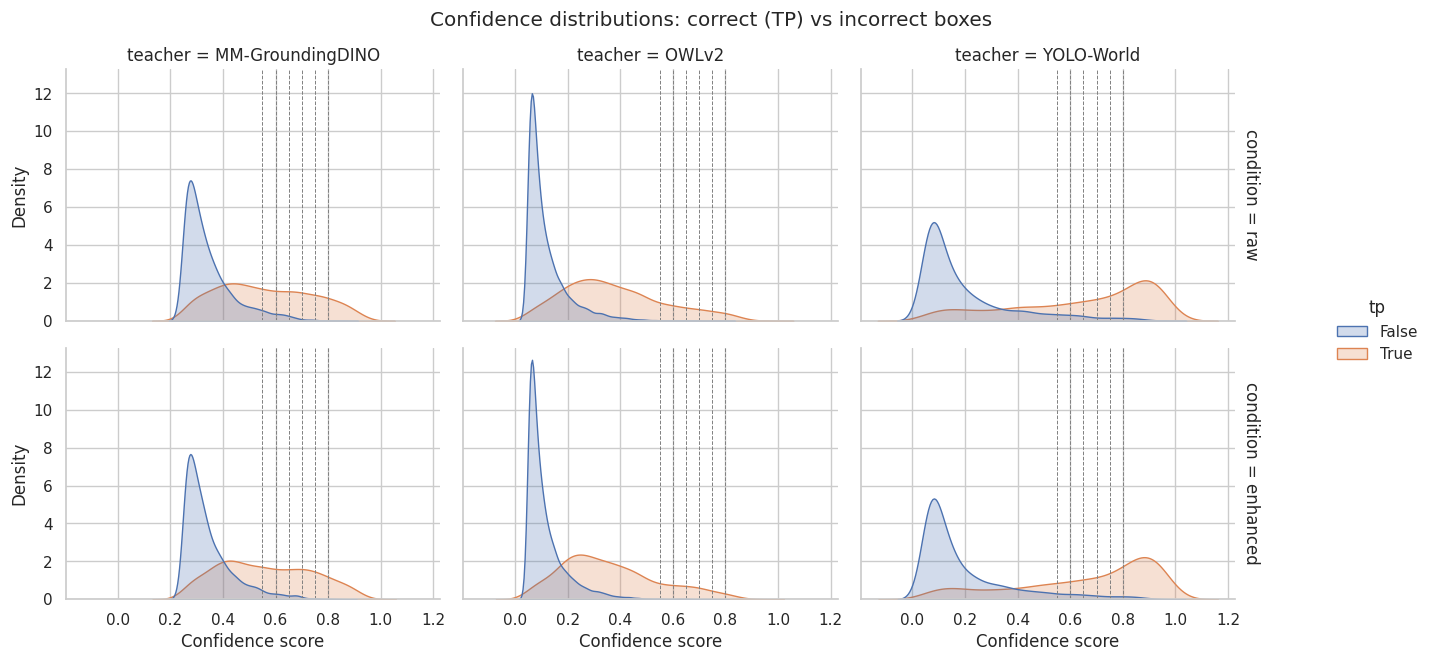

In [ ]:
import seaborn as sns
sns.set_theme(style="whitegrid")

g = sns.displot(
    DF, x="score", hue="tp", col="teacher", row="condition",
    kind="kde", fill=True, common_norm=False, height=3.2, aspect=1.4,
    facet_kws={"margin_titles": True},
)
g.set_axis_labels("Confidence score", "Density")
for ax in g.axes.flat:
    for t in CFG.thresholds:
        ax.axvline(t, ls="--", lw=0.7, color="grey")
    mark_axis_break(ax)
g.fig.suptitle("Confidence distributions: correct (TP) vs incorrect boxes", y=1.03)
plt.show()


## 10. Analysis B — Precision @ thresholds

`precision = TP / (TP + FP)` over predictions with `score ≥ threshold`, for each (teacher, condition, threshold). This is the primary accuracy criterion for teacher selection.


threshold                     0.55    0.60    0.65    0.70    0.75    0.80
teacher          condition                                                
MM-GroundingDINO enhanced   0.8185  0.8591  0.8958  0.9511  0.9698  0.9775
                 raw        0.8100  0.8618  0.9191  0.9552  0.9713  0.9741
OWLv2            enhanced   0.8622  0.8642  0.9000  0.9375  0.9655  1.0000
                 raw        0.8805  0.8938  0.9104  0.9448  0.9341  0.9756
YOLO-World       enhanced   0.8286  0.8486  0.8736  0.8966  0.9122  0.9313
                 raw        0.8353  0.8577  0.8884  0.9052  0.9195  0.9420

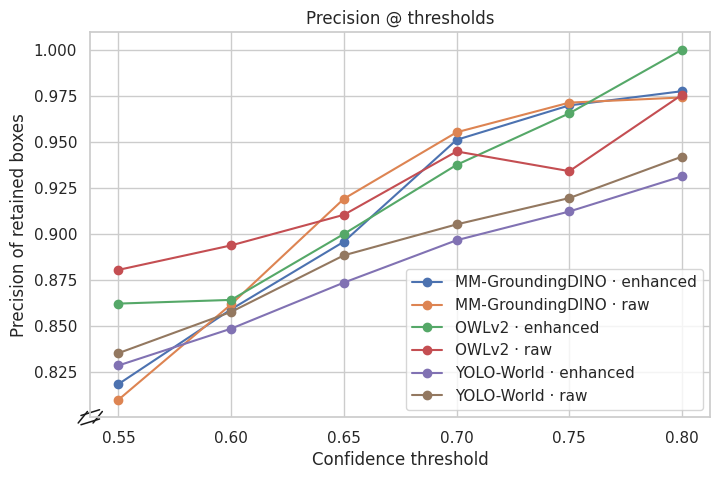

In [ ]:
def precision_table(df, thresholds):
    out = []
    for teacher in df["teacher"].unique():
        for cond in df["condition"].unique():
            sub = df[(df.teacher == teacher) & (df.condition == cond)]
            for t in thresholds:
                kept = sub[sub.score >= t]
                tp = int(kept.tp.sum()); n = len(kept)
                prec = tp / n if n else float("nan")
                out.append({"teacher": teacher, "condition": cond,
                            "threshold": t, "kept_boxes": n,
                            "TP": tp, "precision": round(prec, 4)})
    return pd.DataFrame(out)

PREC = precision_table(DF, CFG.thresholds)
display(PREC.pivot_table(index=["teacher", "condition"], columns="threshold",
                         values="precision"))

# visualise
fig, ax = plt.subplots(figsize=(8, 5))
for (teacher, cond), grp in PREC.groupby(["teacher", "condition"]):
    ax.plot(grp.threshold, grp.precision, marker="o", label=f"{teacher} · {cond}")
ax.set_xlabel("Confidence threshold"); ax.set_ylabel("Precision of retained boxes")
ax.set_title("Precision @ thresholds"); ax.legend()
mark_axis_break(ax)
plt.show()


## 11. Analysis C — Confidence–IoU calibration

Tests whether higher confidence predicts better localisation: scatters each prediction's confidence against its best IoU with ground truth, reporting Pearson/Spearman correlation. A positive, significant correlation confirms threshold filtering is a principled quality gate.


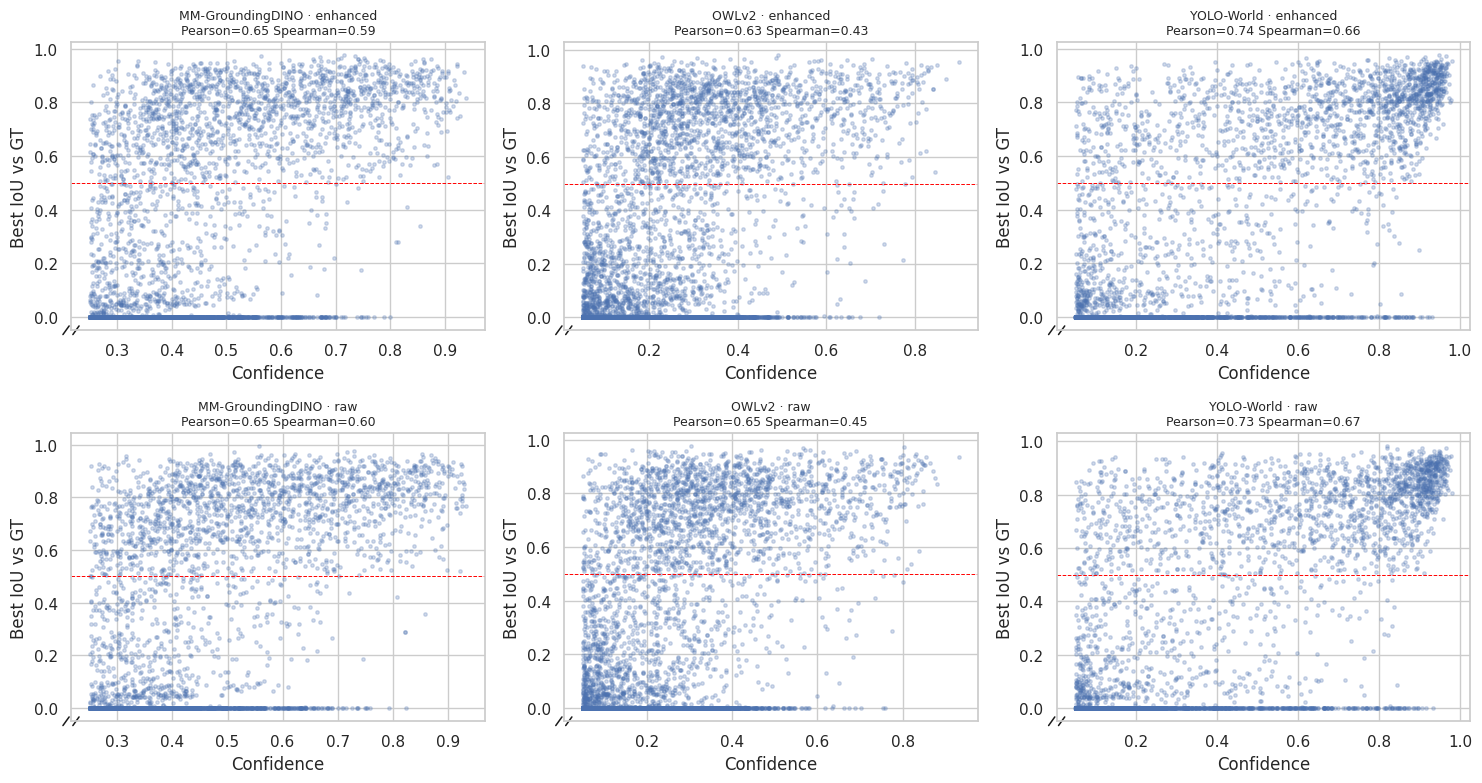

,teacher,condition,pearson_r,spearman_r
0,MM-GroundingDINO,enhanced,0.654,0.587
1,OWLv2,enhanced,0.629,0.434
2,YOLO-World,enhanced,0.742,0.662
3,MM-GroundingDINO,raw,0.649,0.604
4,OWLv2,raw,0.648,0.447
5,YOLO-World,raw,0.731,0.668


In [ ]:
from scipy.stats import pearsonr, spearmanr

fig, axes = plt.subplots(len(DF.condition.unique()), len(DF.teacher.unique()),
                         figsize=(15, 8), squeeze=False)
calib_summary = []
for i, cond in enumerate(sorted(DF.condition.unique())):
    for j, teacher in enumerate(sorted(DF.teacher.unique())):
        sub = DF[(DF.teacher == teacher) & (DF.condition == cond)]
        ax = axes[i][j]
        ax.scatter(sub.score, sub.best_iou, s=6, alpha=0.25)
        ax.axhline(CFG.iou_match, ls="--", lw=0.7, color="red")
        if len(sub) > 2:
            pr = pearsonr(sub.score, sub.best_iou)[0]
            sr = spearmanr(sub.score, sub.best_iou)[0]
        else:
            pr = sr = float("nan")
        calib_summary.append({"teacher": teacher, "condition": cond,
                              "pearson_r": round(pr, 3), "spearman_r": round(sr, 3)})
        ax.set_title(f"{teacher} · {cond}\nPearson={pr:.2f} Spearman={sr:.2f}", fontsize=9)
        ax.set_xlabel("Confidence"); ax.set_ylabel("Best IoU vs GT")
        mark_axis_break(ax)
plt.tight_layout(); plt.show()
display(pd.DataFrame(calib_summary))


## 12. Analysis D — Per-class pseudo-label survival rate

Counts, per class, how many predicted boxes survive at each threshold. Classes collapsing to near-zero survivors flag a coverage problem, motivating a lower threshold, class-specific thresholds, or a human-label fallback. All teacher × condition combinations are shown for comparison.


In [ ]:
def survival_table(df, thresholds, teacher, condition, original_gt_counts):
    '''Return per-class counts of predictions remaining at each threshold,
    and the original ground truth box counts for that class.'''
    sub = df[(df.teacher == teacher) & (df.condition == condition)]
    rows = []
    for c in EXDARK_CLASSES:
        rec = {"class": c, "original_gt_count": original_gt_counts.get(c, 0)} # Add original_gt_count
        cls_sub = sub[sub["class"] == c]
        for t in thresholds:
            rec[f"n>={t}"] = int((cls_sub.score >= t).sum())
        rows.append(rec)
    return pd.DataFrame(rows).set_index("class")


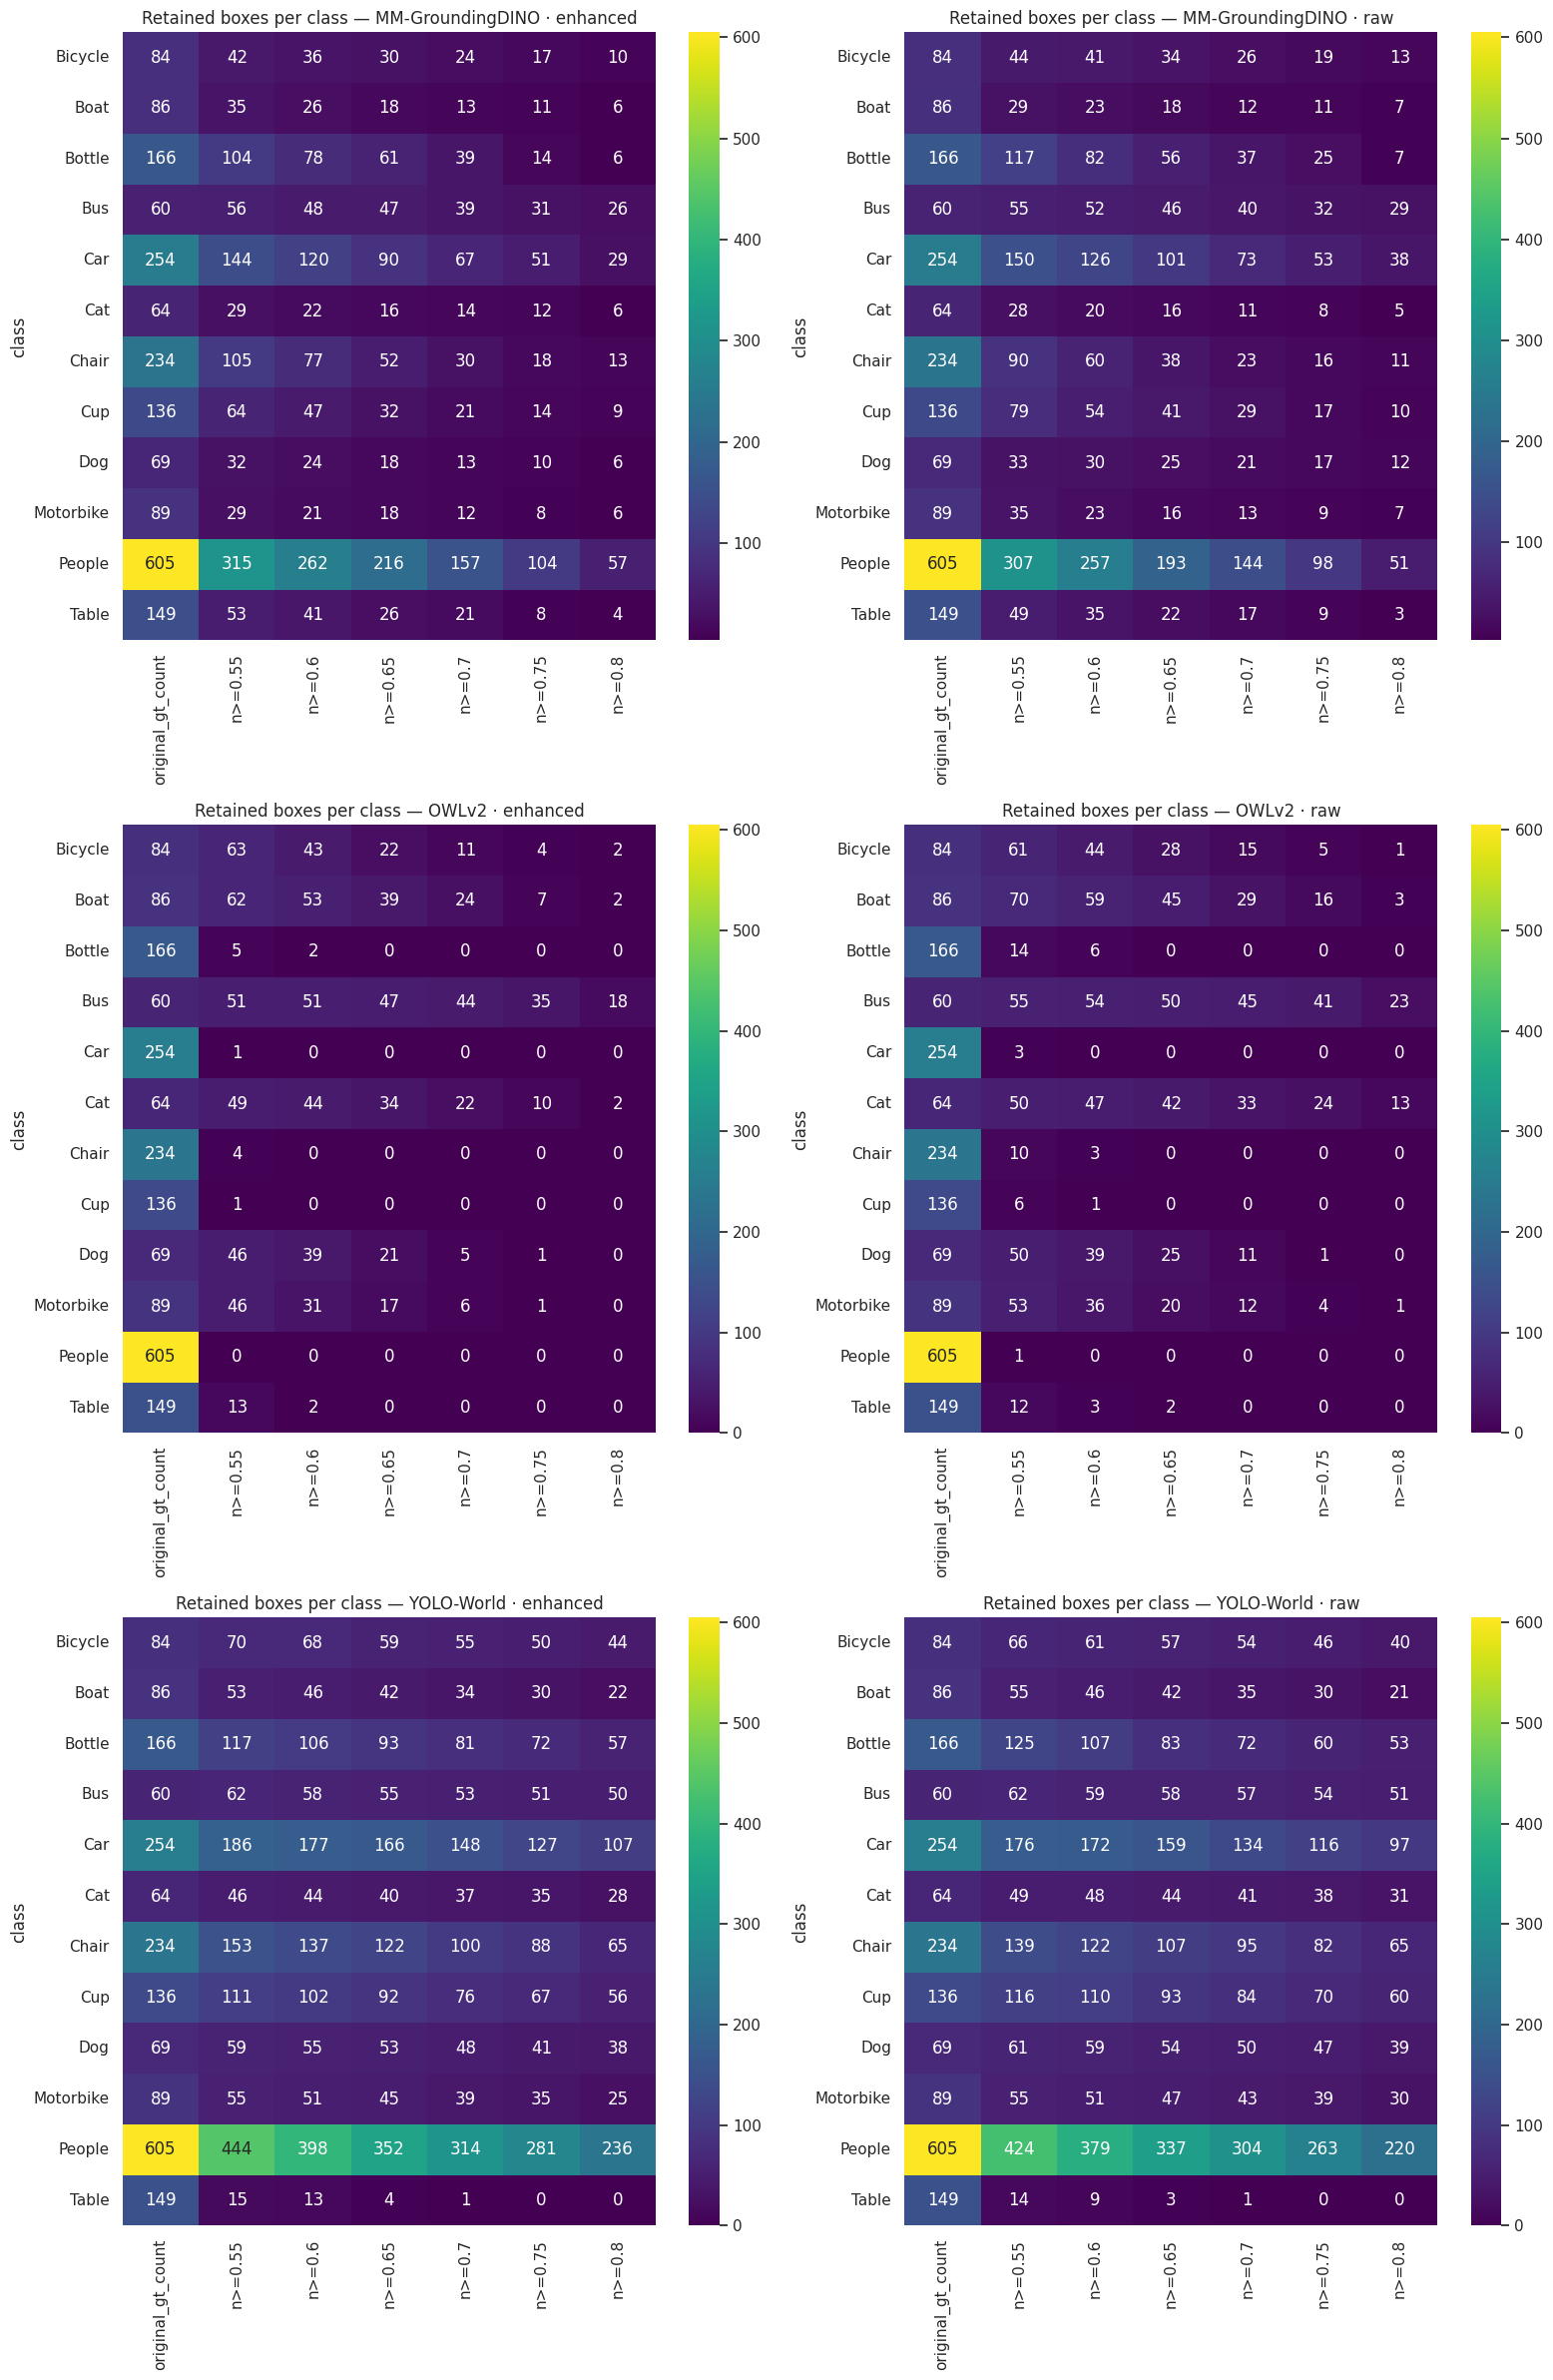


=== Survival table — MM-GroundingDINO · enhanced ===


,original_gt_count,n>=0.55,n>=0.6,n>=0.65,n>=0.7,n>=0.75,n>=0.8
class,,,,,,,
Bicycle,84,42,36,30,24,17,10
Boat,86,35,26,18,13,11,6
Bottle,166,104,78,61,39,14,6
Bus,60,56,48,47,39,31,26
Car,254,144,120,90,67,51,29
Cat,64,29,22,16,14,12,6
Chair,234,105,77,52,30,18,13
Cup,136,64,47,32,21,14,9
Dog,69,32,24,18,13,10,6



=== Survival table — MM-GroundingDINO · raw ===


,original_gt_count,n>=0.55,n>=0.6,n>=0.65,n>=0.7,n>=0.75,n>=0.8
class,,,,,,,
Bicycle,84,44,41,34,26,19,13
Boat,86,29,23,18,12,11,7
Bottle,166,117,82,56,37,25,7
Bus,60,55,52,46,40,32,29
Car,254,150,126,101,73,53,38
Cat,64,28,20,16,11,8,5
Chair,234,90,60,38,23,16,11
Cup,136,79,54,41,29,17,10
Dog,69,33,30,25,21,17,12



=== Survival table — OWLv2 · enhanced ===


...

,original_gt_count,n>=0.55,n>=0.6,n>=0.65,n>=0.7,n>=0.75,n>=0.8
class,,,,,,,
Bicycle,84,61,44,28,15,5,1
Boat,86,70,59,45,29,16,3
Bottle,166,14,6,0,0,0,0
Bus,60,55,54,50,45,41,23
Car,254,3,0,0,0,0,0
Cat,64,50,47,42,33,24,13
Chair,234,10,3,0,0,0,0
Cup,136,6,1,0,0,0,0
Dog,69,50,39,25,11,1,0



=== Survival table — YOLO-World · enhanced ===


,original_gt_count,n>=0.55,n>=0.6,n>=0.65,n>=0.7,n>=0.75,n>=0.8
class,,,,,,,
Bicycle,84,70,68,59,55,50,44
Boat,86,53,46,42,34,30,22
Bottle,166,117,106,93,81,72,57
Bus,60,62,58,55,53,51,50
Car,254,186,177,166,148,127,107
Cat,64,46,44,40,37,35,28
Chair,234,153,137,122,100,88,65
Cup,136,111,102,92,76,67,56
Dog,69,59,55,53,48,41,38



=== Survival table — YOLO-World · raw ===


,original_gt_count,n>=0.55,n>=0.6,n>=0.65,n>=0.7,n>=0.75,n>=0.8
class,,,,,,,
Bicycle,84,66,61,57,54,46,40
Boat,86,55,46,42,35,30,21
Bottle,166,125,107,83,72,60,53
Bus,60,62,59,58,57,54,51
Car,254,176,172,159,134,116,97
Cat,64,49,48,44,41,38,31
Chair,234,139,122,107,95,82,65
Cup,136,116,110,93,84,70,60
Dog,69,61,59,54,50,47,39


In [ ]:
# Calculate original GT counts per class
original_gt_counts = {cls: 0 for cls in EXDARK_CLASSES}
for sample in SAMPLES:
    for gt_class, _ in sample['gt']:
        original_gt_counts[gt_class] += 1

# Plot survival heatmaps for EVERY teacher x condition combination, for completeness.
combos = [(t, c) for t in sorted(DF.teacher.unique()) for c in sorted(DF.condition.unique())]
n = len(combos)
ncols = 2
nrows = (n + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(8 * ncols, 8 * nrows))
axes = axes.flatten() if n > 1 else [axes]

for ax, (teacher, cond) in zip(axes, combos):
    tab = survival_table(DF, CFG.thresholds, teacher, cond, original_gt_counts)
    sns.heatmap(tab, annot=True, fmt="d", cmap="viridis", ax=ax, cbar=True)
    ax.set_title(f"Retained boxes per class — {teacher} · {cond}")

# Hide any unused subplot axes if the grid is not fully filled
for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Also print each table as text for precise inspection
for teacher, cond in combos:
    tab = survival_table(DF, CFG.thresholds, teacher, cond, original_gt_counts)
    print(f"\n=== Survival table — {teacher} · {cond} ===")
    display(tab)


## 13. Selection: best teacher + condition + threshold

Ranks (teacher, condition, threshold) combinations, preferring maximum precision subject to a coverage guard — at least `MIN_PER_CLASS` surviving boxes for the weakest class.


In [ ]:
MIN_PER_CLASS = 10   # require at least this many surviving boxes for the weakest class
MIN_KEPT_BOXES = 1000 # at least this many total boxes across all classes

def min_class_survival(df, teacher, condition, t):
    sub = df[(df.teacher == teacher) & (df.condition == condition)]
    counts = [int((sub[sub['class'] == c].score >= t).sum()) for c in EXDARK_CLASSES]
    return min(counts) if counts else 0

ranking = []
for teacher in sorted(DF.teacher.unique()):
    for cond in sorted(DF.condition.unique()):
        for t in CFG.thresholds:
            sub = DF[(DF.teacher == teacher) & (DF.condition == cond) & (DF.score >= t)]
            n = len(sub); tp = int(sub.tp.sum())
            prec = tp / n if n else float("nan")
            mcs = min_class_survival(DF, teacher, cond, t)
            ranking.append({
                "teacher": teacher, "condition": cond, "threshold": t,
                "precision": round(prec, 4), "kept_boxes": n,
                "min_class_survival": mcs,
                "meets_coverage": mcs >= MIN_PER_CLASS,
                "meets_kept_boxes": n >= MIN_KEPT_BOXES,
            })
RANK = pd.DataFrame(ranking)

eligible = RANK[RANK.meets_coverage & RANK.meets_kept_boxes].copy()
if len(eligible):
    best = eligible.sort_values("precision", ascending=False).iloc[0]
    print("SELECTED CONFIGURATION")
    print("----------------------")
    print(f"  Teacher   : {best.teacher}")
    print(f"  Condition : {best.condition}")
    print(f"  Threshold : {best.threshold}")
    print(f"  Precision : {best.precision}")
    print(f"  Kept boxes: {best.kept_boxes} (>= {MIN_KEPT_BOXES})")
    print(f"  Min class survival: {best.min_class_survival} (>= {MIN_PER_CLASS})")
else:
    print(f"No configuration meets MIN_PER_CLASS={MIN_PER_CLASS} AND MIN_KEPT_BOXES={MIN_KEPT_BOXES}. "
          f"Lower the coverage requirements or the threshold sweep.")

print("\nFull ranking (precision-sorted, coverage-eligible first):")
display(RANK.sort_values(["meets_coverage", "meets_kept_boxes", "precision"], ascending=[False, False, False]))

SELECTED CONFIGURATION
----------------------
  Teacher   : YOLO-World
  Condition : enhanced
  Threshold : 0.6
  Precision : 0.8486
  Kept boxes: 1255 (>= 1000)
  Min class survival: 13 (>= 10)

Full ranking (precision-sorted, coverage-eligible first):


,teacher,condition,threshold,precision,kept_boxes,min_class_survival,meets_coverage,meets_kept_boxes
25,YOLO-World,enhanced,0.60,0.8486,1255,13,True,True
30,YOLO-World,raw,0.55,0.8353,1342,14,True,True
24,YOLO-World,enhanced,0.55,0.8286,1371,15,True,True
0,MM-GroundingDINO,enhanced,0.55,0.8185,1008,29,True,True
6,MM-GroundingDINO,raw,0.55,0.8100,1016,28,True,True
9,MM-GroundingDINO,raw,0.70,0.9552,446,11,True,False
3,MM-GroundingDINO,enhanced,0.70,0.9511,450,12,True,False
8,MM-GroundingDINO,raw,0.65,0.9191,606,16,True,False
2,MM-GroundingDINO,enhanced,0.65,0.8958,624,16,True,False
7,MM-GroundingDINO,raw,0.60,0.8618,803,20,True,False


## 13.1 Per-class F1 score and detection metrics

Per-class precision, recall, F1, and TP/FP/FN counts at `analysis_threshold` (the selected threshold, or 0.75 by default), visualised as a heatmap for every teacher × condition combination.


Using analysis threshold: 0.60

--- MM-GroundingDINO · raw @ Threshold 0.60 ---


,teacher,condition,TP,FP,FN,GT Count,Precision,Recall,F1 Score
class,,,,,,,,,
Bicycle,MM-GroundingDINO,raw,40,1,44,84,0.976,0.476,0.640
Boat,MM-GroundingDINO,raw,19,4,67,86,0.826,0.221,0.349
Bottle,MM-GroundingDINO,raw,59,23,107,166,0.720,0.355,0.476
Bus,MM-GroundingDINO,raw,47,5,13,60,0.904,0.783,0.839
Car,MM-GroundingDINO,raw,113,13,141,254,0.897,0.445,0.595
Cat,MM-GroundingDINO,raw,18,2,46,64,0.900,0.281,0.429
Chair,MM-GroundingDINO,raw,45,15,189,234,0.750,0.192,0.306
Cup,MM-GroundingDINO,raw,41,13,95,136,0.759,0.301,0.432
Dog,MM-GroundingDINO,raw,27,3,42,69,0.900,0.391,0.545


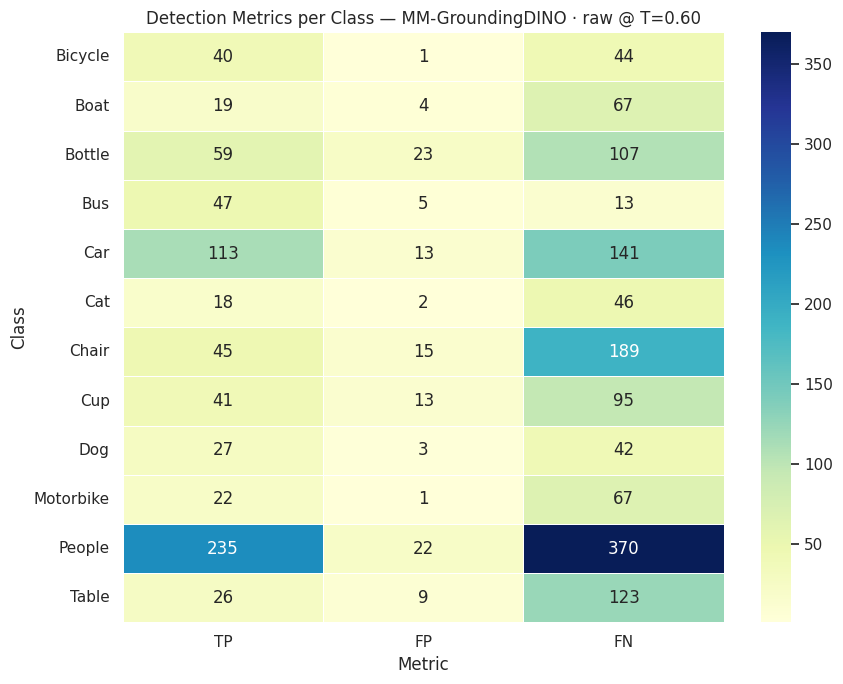


--- MM-GroundingDINO · enhanced @ Threshold 0.60 ---


,teacher,condition,TP,FP,FN,GT Count,Precision,Recall,F1 Score
class,,,,,,,,,
Bicycle,MM-GroundingDINO,enhanced,36,0,48,84,1.000,0.429,0.600
Boat,MM-GroundingDINO,enhanced,19,7,67,86,0.731,0.221,0.339
Bottle,MM-GroundingDINO,enhanced,61,17,105,166,0.782,0.367,0.500
Bus,MM-GroundingDINO,enhanced,44,4,16,60,0.917,0.733,0.815
Car,MM-GroundingDINO,enhanced,111,9,143,254,0.925,0.437,0.594
Cat,MM-GroundingDINO,enhanced,21,1,43,64,0.955,0.328,0.488
Chair,MM-GroundingDINO,enhanced,51,26,183,234,0.662,0.218,0.328
Cup,MM-GroundingDINO,enhanced,39,8,97,136,0.830,0.287,0.426
Dog,MM-GroundingDINO,enhanced,22,2,47,69,0.917,0.319,0.473


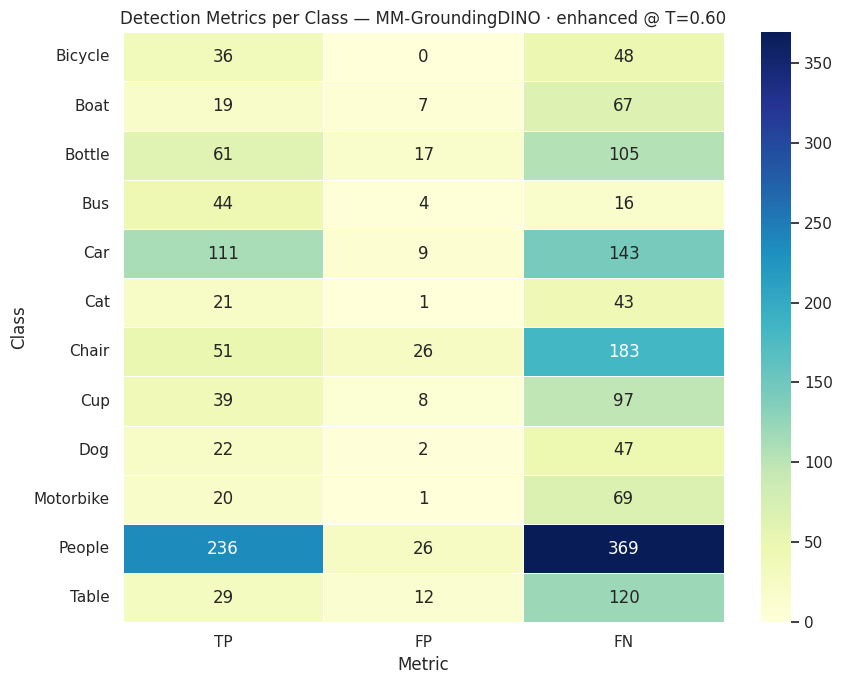


--- OWLv2 · raw @ Threshold 0.60 ---


,teacher,condition,TP,FP,FN,GT Count,Precision,Recall,F1 Score
class,,,,,,,,,
Bicycle,OWLv2,raw,40,4,44,84,0.909,0.476,0.625
Boat,OWLv2,raw,39,20,47,86,0.661,0.453,0.538
Bottle,OWLv2,raw,6,0,160,166,1.000,0.036,0.070
Bus,OWLv2,raw,53,1,7,60,0.981,0.883,0.930
Car,OWLv2,raw,0,0,254,254,0.000,0.000,0.000
Cat,OWLv2,raw,45,2,19,64,0.957,0.703,0.811
Chair,OWLv2,raw,3,0,231,234,1.000,0.013,0.025
Cup,OWLv2,raw,1,0,135,136,1.000,0.007,0.015
Dog,OWLv2,raw,37,2,32,69,0.949,0.536,0.685


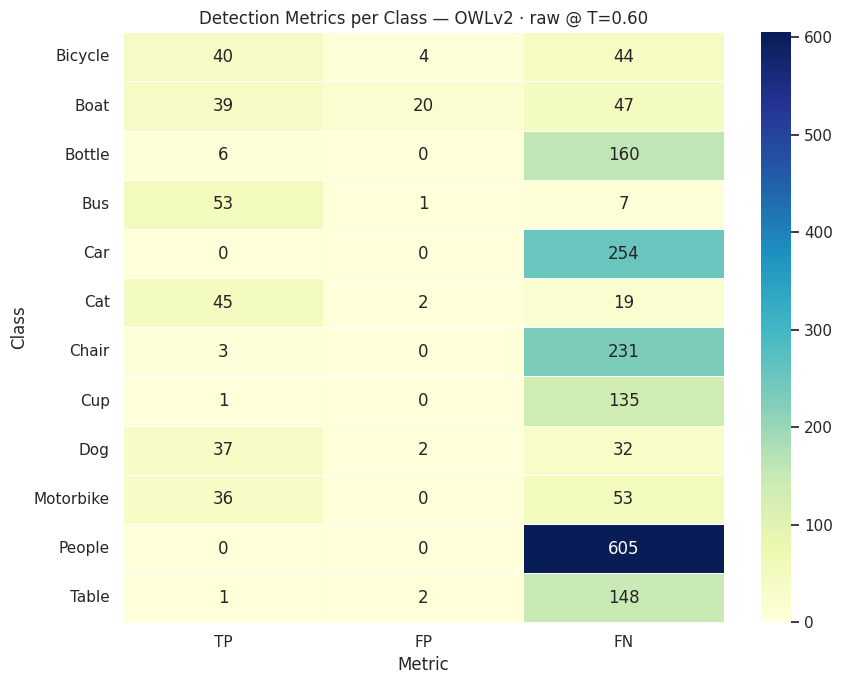


--- OWLv2 · enhanced @ Threshold 0.60 ---


,teacher,condition,TP,FP,FN,GT Count,Precision,Recall,F1 Score
class,,,,,,,,,
Bicycle,OWLv2,enhanced,38,5,46,84,0.884,0.452,0.598
Boat,OWLv2,enhanced,32,21,54,86,0.604,0.372,0.460
Bottle,OWLv2,enhanced,1,1,165,166,0.500,0.006,0.012
Bus,OWLv2,enhanced,51,0,9,60,1.000,0.850,0.919
Car,OWLv2,enhanced,0,0,254,254,0.000,0.000,0.000
Cat,OWLv2,enhanced,42,2,22,64,0.955,0.656,0.778
Chair,OWLv2,enhanced,0,0,234,234,0.000,0.000,0.000
Cup,OWLv2,enhanced,0,0,136,136,0.000,0.000,0.000
Dog,OWLv2,enhanced,35,4,34,69,0.897,0.507,0.648


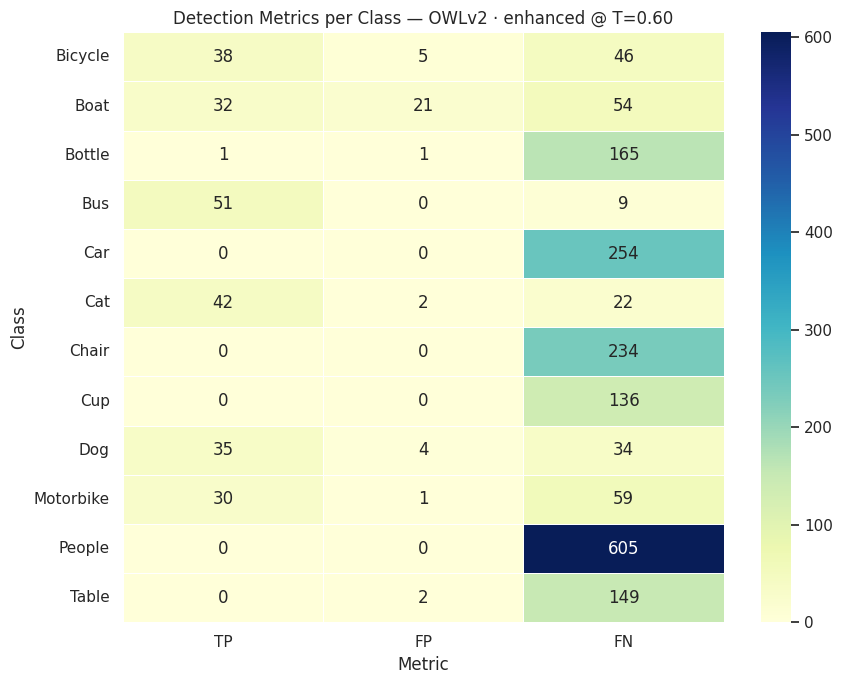


--- YOLO-World · raw @ Threshold 0.60 ---


,teacher,condition,TP,FP,FN,GT Count,Precision,Recall,F1 Score
class,,,,,,,,,
Bicycle,YOLO-World,raw,55,6,29,84,0.902,0.655,0.759
Boat,YOLO-World,raw,37,9,49,86,0.804,0.430,0.561
Bottle,YOLO-World,raw,80,27,86,166,0.748,0.482,0.586
Bus,YOLO-World,raw,56,3,4,60,0.949,0.933,0.941
Car,YOLO-World,raw,150,22,104,254,0.872,0.591,0.704
Cat,YOLO-World,raw,39,9,25,64,0.812,0.609,0.696
Chair,YOLO-World,raw,105,17,129,234,0.861,0.449,0.590
Cup,YOLO-World,raw,84,26,52,136,0.764,0.618,0.683
Dog,YOLO-World,raw,45,14,24,69,0.763,0.652,0.703


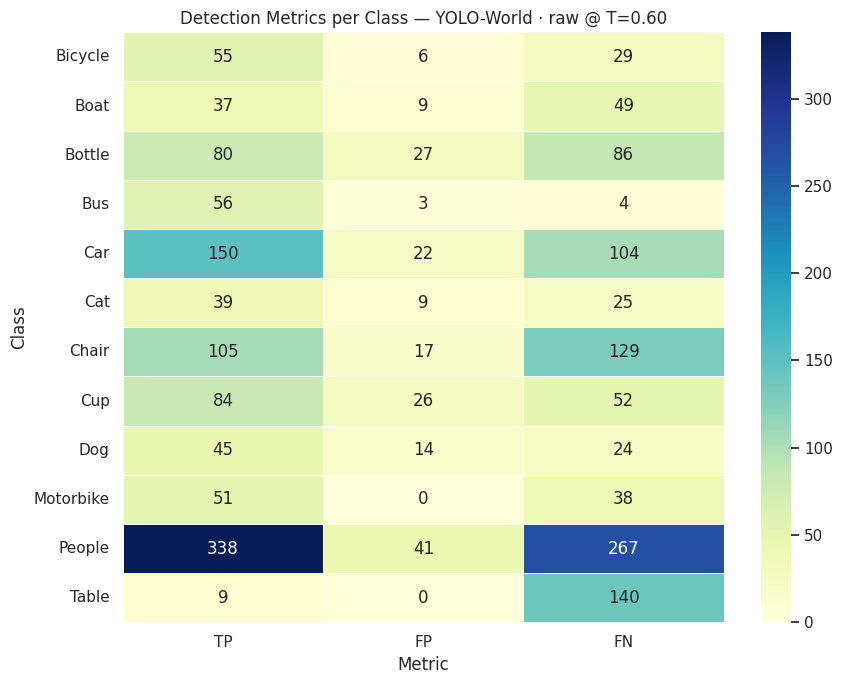


--- YOLO-World · enhanced @ Threshold 0.60 ---


,teacher,condition,TP,FP,FN,GT Count,Precision,Recall,F1 Score
class,,,,,,,,,
Bicycle,YOLO-World,enhanced,58,10,26,84,0.853,0.690,0.763
Boat,YOLO-World,enhanced,33,13,53,86,0.717,0.384,0.500
Bottle,YOLO-World,enhanced,84,22,82,166,0.792,0.506,0.618
Bus,YOLO-World,enhanced,53,5,7,60,0.914,0.883,0.898
Car,YOLO-World,enhanced,153,24,101,254,0.864,0.602,0.710
Cat,YOLO-World,enhanced,36,8,28,64,0.818,0.562,0.667
Chair,YOLO-World,enhanced,115,22,119,234,0.839,0.491,0.620
Cup,YOLO-World,enhanced,78,24,58,136,0.765,0.574,0.655
Dog,YOLO-World,enhanced,43,12,26,69,0.782,0.623,0.694


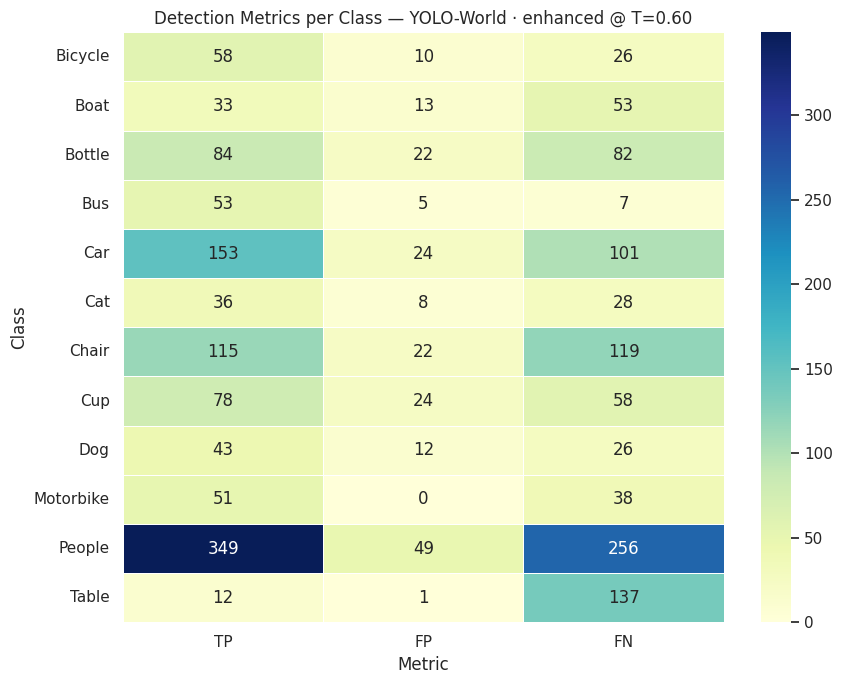


--- F1 Score Comparison Across Teachers and Conditions @ T=0.60 ---


Teacher   MM-GroundingDINO           OWLv2        YOLO-World       
Condition         enhanced    raw enhanced    raw   enhanced    raw
Class                                                              
Bicycle              0.600  0.640    0.598  0.625      0.763  0.759
Boat                 0.339  0.349    0.460  0.538      0.500  0.561
Bottle               0.500  0.476    0.012  0.070      0.618  0.586
Bus                  0.815  0.839    0.919  0.930      0.898  0.941
Car                  0.594  0.595    0.000  0.000      0.710  0.704
Cat                  0.488  0.429    0.778  0.811      0.667  0.696
Chair                0.328  0.306    0.000  0.025      0.620  0.590
Cup                  0.426  0.432    0.000  0.015      0.655  0.683
Dog                  0.473  0.545    0.648  0.685      0.694  0.703
Motorbike            0.364  0.393    0.500  0.576      0.729  0.729
People               0.544  0.545    0.000  0.000      0.696  0.687
Table                0.305  0.283    0.000  0.013      0.148  0.114

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Determine the threshold to use for this analysis
# Use the 'best.threshold' if available, otherwise default to 0.75
analysis_threshold = best.threshold if 'best' in locals() else 0.75

print(f"Using analysis threshold: {analysis_threshold:.2f}")

# Ensure original_gt_counts is available
# (This dict should already be in the kernel state from a previous cell)
if 'original_gt_counts' not in locals():
    original_gt_counts = {cls: 0 for cls in EXDARK_CLASSES}
    for sample in SAMPLES:
        for gt_class, _ in sample['gt']:
            original_gt_counts[gt_class] += 1

all_class_metrics = []

for teacher_name in DF["teacher"].unique():
    for condition_name in DF["condition"].unique():
        # Filter predictions for the current teacher, condition, and threshold
        subset_df = DF[(DF.teacher == teacher_name) & (DF.condition == condition_name) & (DF.score >= analysis_threshold)]

        class_metrics = []
        for cls in EXDARK_CLASSES:
            class_subset = subset_df[subset_df['class'] == cls]
            tp_count = class_subset['tp'].sum()
            fp_count = len(class_subset) - tp_count

            # FN is total GTs for this class minus the ones correctly detected (TPs)
            gt_count = original_gt_counts.get(cls, 0)
            fn_count = max(0, gt_count - tp_count) # Ensure FN is not negative

            # Calculate precision, recall, f1 for this class
            precision = tp_count / (tp_count + fp_count) if (tp_count + fp_count) > 0 else 0.0
            recall = tp_count / (tp_count + fn_count) if (tp_count + fn_count) > 0 else 0.0
            f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0

            class_metrics.append({
                "teacher": teacher_name,
                "condition": condition_name,
                "class": cls,
                "TP": int(tp_count),
                "FP": int(fp_count),
                "FN": int(fn_count),
                "GT Count": int(gt_count),
                "Precision": round(precision, 3),
                "Recall": round(recall, 3),
                "F1 Score": round(f1, 3)
            })

        class_metrics_df = pd.DataFrame(class_metrics).set_index('class')
        all_class_metrics.append(class_metrics_df)

        print(f"\n--- {teacher_name} · {condition_name} @ Threshold {analysis_threshold:.2f} ---")
        display(class_metrics_df)

        # Plot custom 'confusion matrix' (TP, FP, FN heatmap)
        cm_data = class_metrics_df[['TP', 'FP', 'FN']]

        plt.figure(figsize=(9, 7))
        sns.heatmap(cm_data, annot=True, fmt="d", cmap="YlGnBu", linewidths=.5)
        plt.title(f"Detection Metrics per Class — {teacher_name} · {condition_name} @ T={analysis_threshold:.2f}")
        plt.xlabel("Metric")
        plt.ylabel("Class")
        plt.tight_layout()
        plt.show()

# Create a single DataFrame for all F1 scores for easier comparison
f1_comparison_data = []
for metrics_df in all_class_metrics:
    for idx, row in metrics_df.iterrows():
        f1_comparison_data.append({
            'Teacher': row['teacher'],
            'Condition': row['condition'],
            'Class': idx,
            'F1 Score': row['F1 Score']
        })

f1_comparison_df = pd.DataFrame(f1_comparison_data)
f1_pivot = f1_comparison_df.pivot_table(index='Class', columns=['Teacher', 'Condition'], values='F1 Score')

print(f"\n--- F1 Score Comparison Across Teachers and Conditions @ T={analysis_threshold:.2f} ---")
display(f1_pivot)


## Qualitative Check: Visual Inspection

Plots each sample image with ground-truth boxes (solid green) and each teacher's top predictions (dashed orange, labelled with class and confidence) overlaid, to see at a glance whether a teacher misses objects, mislocalises them, or is just noisy.


Inspecting sample image: 2015_01413.jpg (Primary class: Bottle)
Ground Truth boxes: [('Bottle', [285.0, 315.0, 323.0, 403.0]), ('Table', [218.0, 360.0, 372.0, 497.0]), ('Chair', [3.0, 254.0, 129.0, 496.0]), ('People', [41.0, 141.0, 315.0, 489.0])]
Legend: solid green = ground truth, dashed orange = top-10 predictions by confidence



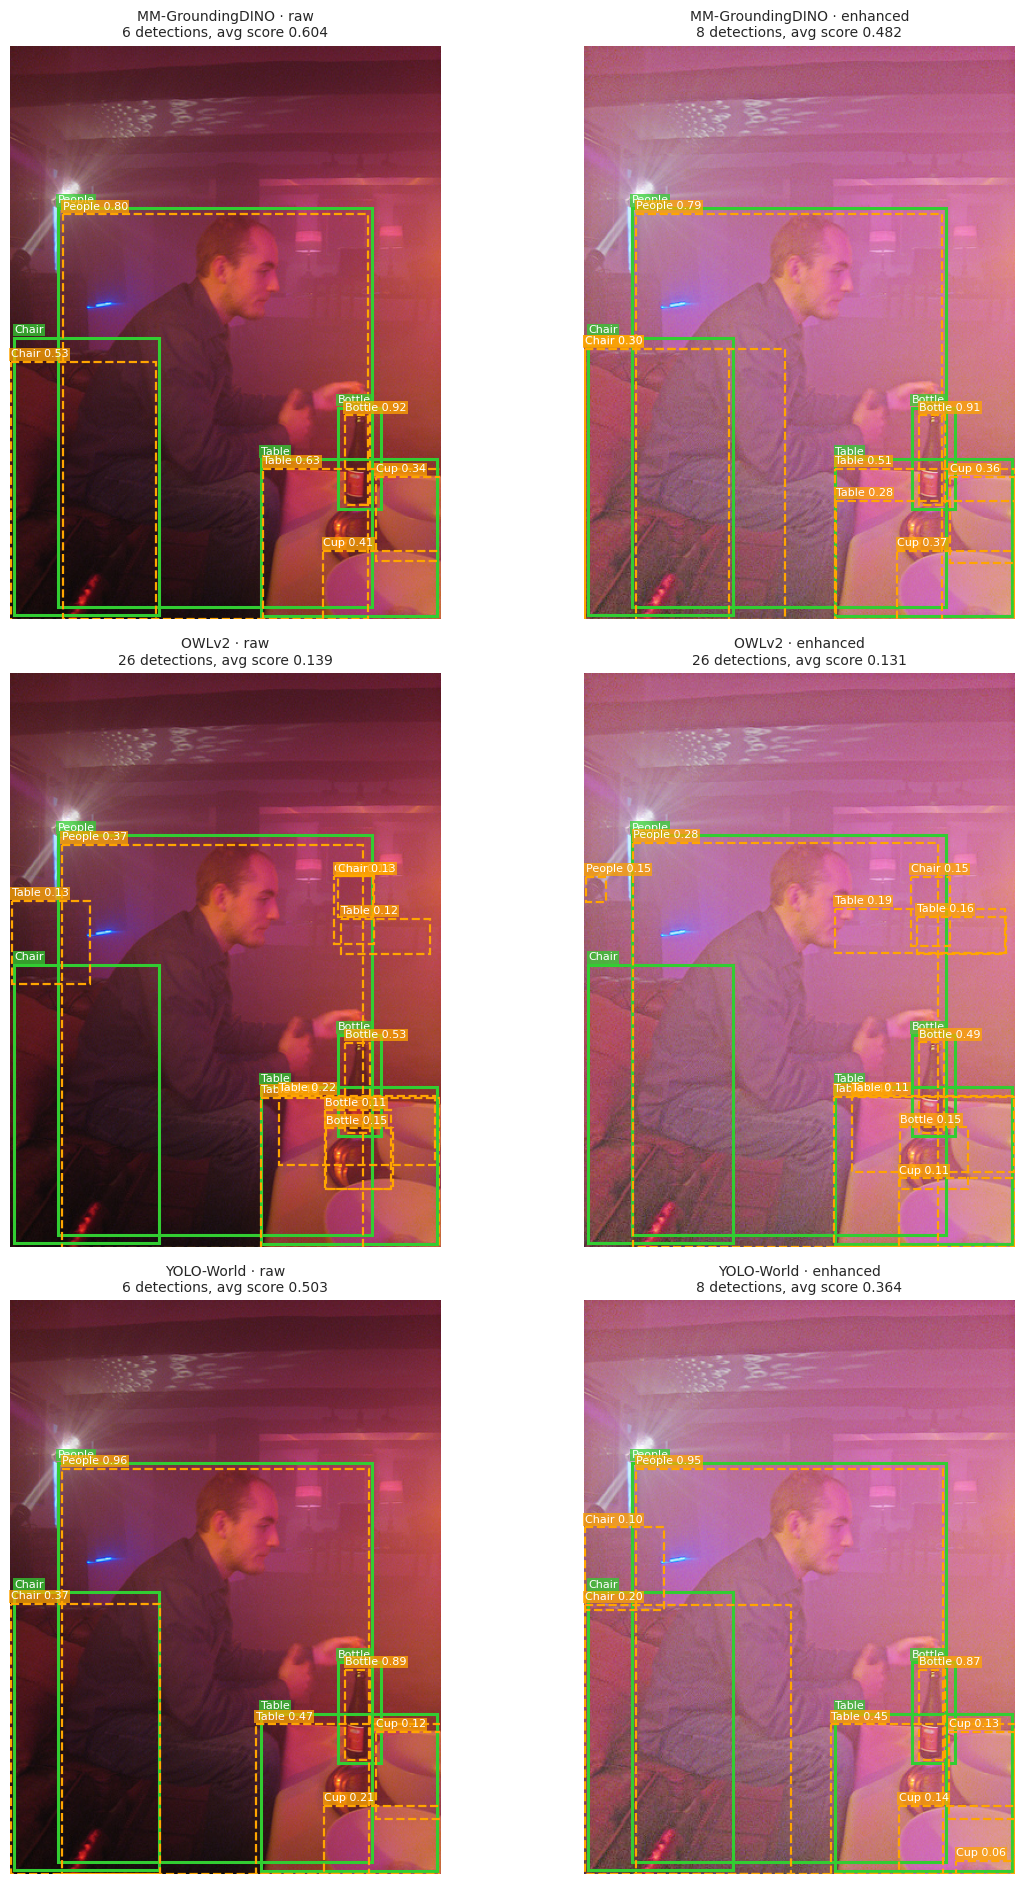


--- MM-GroundingDINO · raw ---
Total detections: 6
Top 5 detections (class, score):
     class     score
0  People  0.803173
1   Table  0.628206
2  Bottle  0.922547
3   Chair  0.527402
4     Cup  0.405199
Average score: 0.604

--- MM-GroundingDINO · enhanced ---
Total detections: 8
Top 5 detections (class, score):
     class     score
0  People  0.785639
1   Table  0.506715
2  Bottle  0.906338
3     Cup  0.367316
4   Chair  0.352488
Average score: 0.482

--- OWLv2 · raw ---
Total detections: 26
Top 5 detections (class, score):
     class     score
0  People  0.096627
1   Chair  0.131554
2   Chair  0.140134
3   Table  0.064359
4   Table  0.127676
Average score: 0.139

--- OWLv2 · enhanced ---
Total detections: 26
Top 5 detections (class, score):
     class     score
0  Bottle  0.052949
1  People  0.150280
2   Chair  0.082788
3   Chair  0.153889
4  People  0.067768
Average score: 0.131

--- YOLO-World · raw ---
Total detections: 6
Top 5 detections (class, score):
     class     score
0 

In [ ]:
# ── Qualitative check: plot the image with ground truth and predicted boxes ──
import matplotlib.patches as patches

# Show up to this many highest-confidence predictions per panel, to keep the plot readable
QUAL_TOP_K = 10

def draw_boxes(ax, boxes_with_labels, color, linestyle="-", linewidth=2.0):
    # boxes_with_labels: list of (label_text, [x1,y1,x2,y2])
    for label_text, box in boxes_with_labels:
        x1, y1, x2, y2 = box
        rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                 linewidth=linewidth, edgecolor=color,
                                 facecolor="none", linestyle=linestyle)
        ax.add_patch(rect)
        ax.text(x1, max(y1 - 4, 0), label_text, color="white", fontsize=8,
                bbox=dict(facecolor=color, alpha=0.75, pad=1, edgecolor="none"))

def plot_qualitative_panel(ax, image, gt_boxes, det_boxes, title):
    ax.imshow(image)
    gt_labelled = [(cls, box) for cls, box in gt_boxes]
    draw_boxes(ax, gt_labelled, color="limegreen", linestyle="-", linewidth=2.2)
    top_dets = sorted(det_boxes, key=lambda d: d[2], reverse=True)[:QUAL_TOP_K]
    det_labelled = [(f"{cls} {score:.2f}", box) for cls, box, score in top_dets]
    draw_boxes(ax, det_labelled, color="orange", linestyle="--", linewidth=1.6)
    ax.set_title(title, fontsize=10)
    ax.axis("off")

# Select a sample image for inspection
_debug_sample = SAMPLES[0]
_debug_raw_img = Image.open(_debug_sample["path"]).convert("RGB")
_debug_enh_img = enhance_image(_debug_raw_img) if "enhanced" in DF["condition"].unique() else _debug_raw_img

print(f"Inspecting sample image: {_debug_sample['filename']} (Primary class: {_debug_sample['primary_class']})")
print(f"Ground Truth boxes: {_debug_sample['gt']}")
print(f"Legend: solid green = ground truth, dashed orange = top-{QUAL_TOP_K} predictions by confidence\n")

gdino_raw_dets = run_gdino(_debug_raw_img)
gdino_enh_dets = run_gdino(_debug_enh_img)
owlv2_raw_dets = run_owlv2(_debug_raw_img)
owlv2_enh_dets = run_owlv2(_debug_enh_img)
yoloworld_raw_dets = run_yoloworld(_debug_raw_img)
yoloworld_enh_dets = run_yoloworld(_debug_enh_img)

configs = [
    ("MM-GroundingDINO · raw",      _debug_raw_img, gdino_raw_dets),
    ("MM-GroundingDINO · enhanced", _debug_enh_img, gdino_enh_dets),
    ("OWLv2 · raw",                 _debug_raw_img, owlv2_raw_dets),
    ("OWLv2 · enhanced",            _debug_enh_img, owlv2_enh_dets),
    ("YOLO-World · raw",            _debug_raw_img, yoloworld_raw_dets),
    ("YOLO-World · enhanced",       _debug_enh_img, yoloworld_enh_dets),
]

fig, axes = plt.subplots(3, 2, figsize=(13, 19))
axes = axes.flatten()
for ax, (title, img, dets) in zip(axes, configs):
    n_det = len(dets)
    avg_score = (sum(d[2] for d in dets) / n_det) if n_det else 0.0
    plot_qualitative_panel(ax, img, _debug_sample["gt"], dets,
                           f"{title}\n{n_det} detections, avg score {avg_score:.3f}")
plt.tight_layout()
plt.show()

# Print the same summary stats as before, for precise reference alongside the plot
for title, _, dets in configs:
    print(f"\n--- {title} ---")
    print(f"Total detections: {len(dets)}")
    if dets:
        print("Top 5 detections (class, score):\n",
              pd.DataFrame(dets, columns=['class', 'bbox', 'score']).head()[['class', 'score']])
        print(f"Average score: {np.mean([d[2] for d in dets]):.3f}")

# Also check if the PROMPT_MAP is being used correctly across teachers
print("\n--- Prompt Map Check ---")
print(f"EXDARK_CLASSES: {EXDARK_CLASSES}")
print(f"PROMPTS (used by VLMs): {PROMPTS}")
print(f"PROMPT_TO_CLASS (reverse map): {PROMPT_TO_CLASS}")


## 14. Persist results

Saves the raw prediction records and summary tables to the new Drive output folder (`MyDrive/ExDark_dataset/phase0_outputs_yoloworld_v8/`) so Phase 1 can reuse the selected teacher, condition, and threshold without rerunning Phase 0.


In [ ]:
import json
DF.to_csv(os.path.join(PHASE0_OUTPUT_DIR, "prediction_records.csv"), index=False)
PREC.to_csv(os.path.join(PHASE0_OUTPUT_DIR, "precision_at_thresholds.csv"), index=False)
RANK.to_csv(os.path.join(PHASE0_OUTPUT_DIR, "selection_ranking.csv"), index=False)

if len(eligible):
    decision = {
        "selected_teacher": best.teacher,
        "selected_condition": best.condition,
        "selected_threshold": float(best.threshold),
        "precision": float(best.precision),
        "kept_boxes": int(best.kept_boxes),
        "min_class_survival": int(best.min_class_survival),
        "min_per_class_requirement": MIN_PER_CLASS,
        "sample_size": len(SAMPLES),
    }
    with open(os.path.join(PHASE0_OUTPUT_DIR, "phase0_decision.json"), "w") as f:
        json.dump(decision, f, indent=2)
    print("Saved decision:", decision)

print("\nOutputs written to", PHASE0_OUTPUT_DIR)
print(os.listdir(PHASE0_OUTPUT_DIR))


Saved decision: {'selected_teacher': 'YOLO-World', 'selected_condition': 'enhanced', 'selected_threshold': 0.6, 'precision': 0.8486, 'kept_boxes': 1255, 'min_class_survival': 13, 'min_per_class_requirement': 10, 'sample_size': 600}

Outputs written to /content/drive/MyDrive/ExDark_dataset/phase0_outputs_yoloworld_v8
['prediction_records.csv', 'precision_at_thresholds.csv', 'selection_ranking.csv', 'phase0_decision.json']


## 15. What Phase 0 hands to Phase 1

`phase0_decision.json` (in the new Drive output folder) records the selected teacher, image condition, and confidence threshold. Phase 1 applies that teacher to the full training split at the selected threshold to build Condition C (enhanced + VLM pseudo-labels), alongside Condition A (raw + human labels) and Condition B (enhanced + human labels).